# 01 — Auditoría Silver, Huérfanos, Baseline Contrafactual y Guardrails

**Contexto operativo del equipo (`rb06` · IndesIAhack 2026):**
- **Base de datos primaria:** Databricks Unity Catalog (`dat_hack_rb06.rbe.*`), consultada por HTTPS (`443`) desde `backend/` (`backendoficial`) y React (`frontend/`).
- **Base de datos secundaria (standby):** Azure PostgreSQL (`dat-hack-rb06-pgsql`) mediante `databricks/scripts/optional_sync_postgres.py`.
- **Copilot / LLM:** Databricks Foundation Model Endpoint `databricks-claude-haiku-5-5` (`READY`) sobre `evidencia_json`.

**Objetivo de este cuaderno:**
1. Verificar la inferencia de provincia e imputación de festivos (nacionales en todos + regionales cuando `corr_score >= 0.35`) para los **11 restaurantes huérfanos**.
2. Construir el **Baseline Contrafactual Dual** (`log1p(ventas)` y `log1p(tickets)`) mediante **LOO bilateral** + **LightGBM Quantile OOF (6 bloques, purged buffer ±14 días)** + **bandas CQR** y señales de Capa 2 (`z_peer_diff`, `z_cross_channel`).
3. Auditar el embudo granular de **Guardrails deterministas** (alineado con `DetectorPanel.jsx`) y comprobar visualmente la neutralización del **apagón 2025-04-28** y la **DANA de Valencia**.


In [4]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "databricks" / "src" / "config.py").is_file())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from databricks.src.config import get_outputs_dir
from databricks.src.silver import load_raw_datasets, prepare_silver_data
from databricks.src.features import build_features_and_baselines
from databricks.src.guardrails import apply_guardrails, guardrail_funnel_summary

pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 120

t0 = time.perf_counter()
ventas, restaurantes, calendario = load_raw_datasets()
silver = prepare_silver_data(ventas, restaurantes, calendario)
print(f"Silver preparado en {time.perf_counter() - t0:.2f}s | Filas: {len(silver['df']):,} | Series: {silver['n_series']}")


Silver preparado en 36.58s | Filas: 1,377,194 | Series: 1325


In [5]:
# Auditoría de los 11 restaurantes huérfanos y cobertura festiva
orphan_df = silver["orphan_inference"].sort_values("corr_score", ascending=False)
display(orphan_df)

df_s = silver["df"]
orph_jan6 = df_s[(df_s["is_orphan_master"]) & (df_s["fecha"] == pd.Timestamp("2024-01-06"))]
print(f"Huérfanos el 2024-01-06 (Reyes): {len(orph_jan6)} filas | excluidas por festivo = {int(orph_jan6['in_holiday_excl'].sum())}")
print(f"Reformas detectadas (>=7d): {len(silver['reformas'])} episodios en {silver['reformas']['restaurante_id'].nunique()} restaurantes")


,restaurante_id,provincia_inferida,ccaa_inferida,corr_score,n_regional_days
9,R393,barcelona,cataluna,0.8408,74
8,R390,barcelona,cataluna,0.7870,399
0,R158,zaragoza,aragon,0.7386,323
1,R216,sevilla,andalucia,0.7371,251
10,R549,madrid,comunidad-de-madrid,0.7057,167
5,R369,castellon,comunidad-valenciana,0.6828,122
7,R377,madrid,comunidad-de-madrid,0.5905,57
3,R303,castellon,comunidad-valenciana,0.5228,338
6,R371,madrid,comunidad-de-madrid,0.5084,238
4,R362,baleares,islas-baleares,0.3758,161


Huérfanos el 2024-01-06 (Reyes): 23 filas | excluidas por festivo = 23
Reformas detectadas (>=7d): 89 episodios en 64 restaurantes


In [6]:
# Construcción (o carga en caché) de Capa 1 (LOO + OOF LightGBM Quantile + CQR) + Capa 2 + Guardrails
out_dir = get_outputs_dir()
feat_cache = out_dir / "silver_features.parquet"
USE_CACHE = True

t1 = time.perf_counter()
if USE_CACHE and feat_cache.is_file():
    df_feat = pd.read_parquet(feat_cache)
    print(f"Features cargadas desde caché en {time.perf_counter() - t1:.2f}s ({len(df_feat):,} filas)")
else:
    df_feat = build_features_and_baselines(silver, n_folds=6, purge_days=14)
    df_feat = apply_guardrails(df_feat)
    print(f"Features + OOF LightGBM Quantile + CQR completados en {time.perf_counter() - t1:.1f}s")
    df_feat.to_parquet(feat_cache, index=False, coerce_timestamps="us", allow_truncated_timestamps=True)
    silver["restaurants_dim"].to_parquet(out_dir / "restaurants_dim.parquet", index=False)

clean_eval = df_feat["is_eligible_for_alert"] & (df_feat["z_max"] < 3.0)
cov_v = float(((df_feat.loc[clean_eval, "ventas"] >= df_feat.loc[clean_eval, "ventas_p05"]) &
               (df_feat.loc[clean_eval, "ventas"] <= df_feat.loc[clean_eval, "ventas_p95"])).mean())
cov_t = float(((df_feat.loc[clean_eval, "tickets"] >= df_feat.loc[clean_eval, "tickets_p05"]) &
               (df_feat.loc[clean_eval, "tickets"] <= df_feat.loc[clean_eval, "tickets_p95"])).mean())
wape_v = float((df_feat.loc[clean_eval, "ventas"] - df_feat.loc[clean_eval, "ventas_esperadas"]).abs().sum() /
               df_feat.loc[clean_eval, "ventas"].sum())
print(f"Cobertura CQR (días limpios): ventas={cov_v:.3f}, tickets={cov_t:.3f} | WAPE ventas={100*wape_v:.2f}%")


Features cargadas desde caché en 6.36s (1,377,194 filas)
Cobertura CQR (días limpios): ventas=0.915, tickets=0.916 | WAPE ventas=12.66%


In [7]:
# Embudo oficial y desglose granular de exclusion_reason (contrato UI DetectorPanel)
funnel = guardrail_funnel_summary(df_feat)
display(funnel)
print("Desglose exacto de exclusion_reason en series_summary:")
display(df_feat["exclusion_reason"].fillna("normal").value_counts().reset_index(name="filas").rename(columns={"index": "exclusion_reason"}))
print("Distribución por canal en filas elegibles:")
display(df_feat.loc[df_feat["is_eligible_for_alert"]].groupby("canal").size().reset_index(name="filas_elegibles"))


,regla,filas_afectadas,pct_total
0,1. Sin histórico (< 2023-08-05),36418,2.64
1,2. Festivos / víspera_festivo / especiales,103607,7.52
2,3. Ciclo de vida (56d apertura / 28d cierre),15016,1.09
3,4. Reformas (+-7d en cierres >=7d),1764,0.13
4,5. Canal pequeño esperado (<150 EUR o <25 tk),110546,8.03
5,6. Día neutro sistémico (>=35% CCAA/Nac),97938,7.11
6,TOTAL UNIVERSO CANDIDATO ELEGIBLE,1081923,78.56


Desglose exacto de exclusion_reason en series_summary:


,exclusion_reason,filas
0,normal,1081923
1,canal_pequeno,99158
2,festivo,43396
3,dia_neutro,41512
4,vispera_festivo,38875
5,sin_historico,36418
6,fecha_especial,20858
7,apertura,12339
8,reforma,1449
9,cierre,1266


Distribución por canal en filas elegibles:


,canal,filas_elegibles
0,autoking,278549
1,domicilio,314067
2,sala,489307


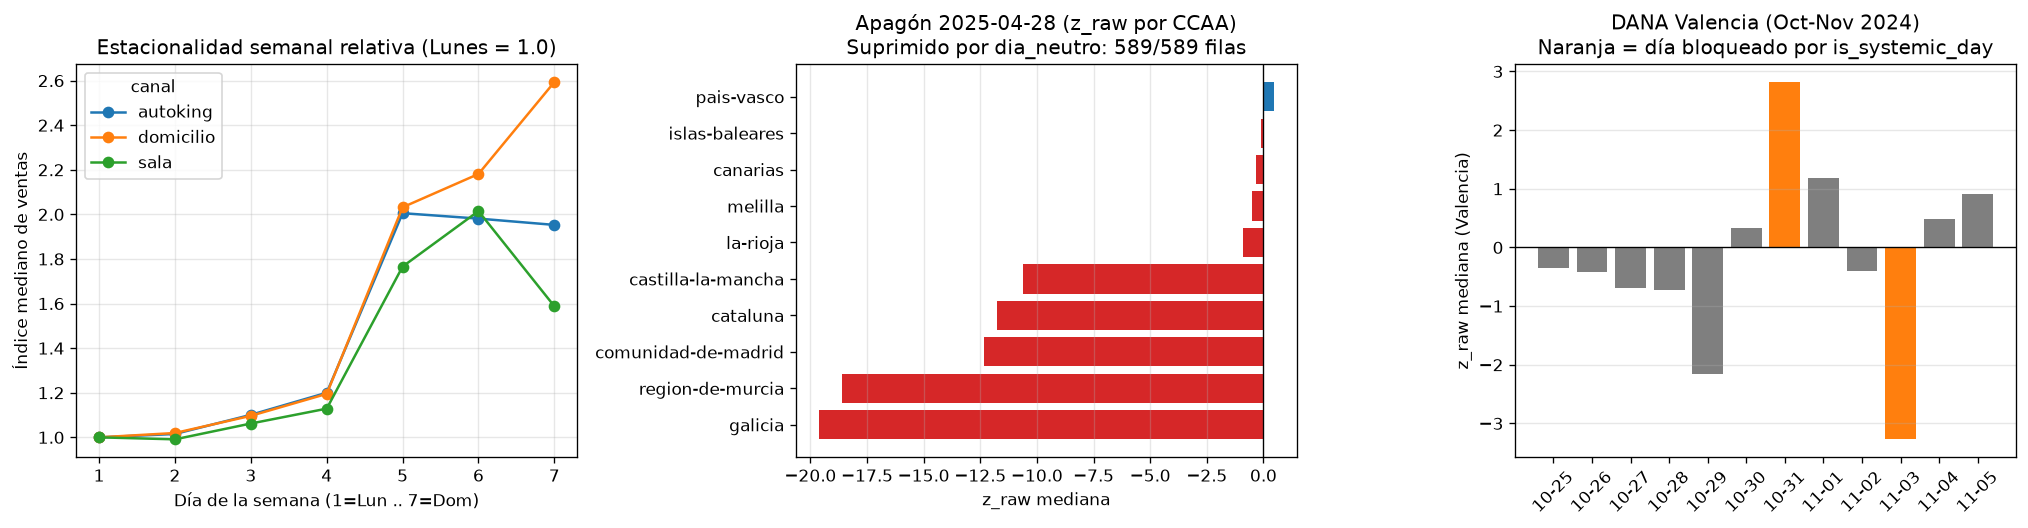

In [8]:
# Visualización de estacionalidad y shocks sistémicos neutralizados
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

dow_tbl = df_feat.groupby(["canal", "dia_semana"])["ventas"].median().unstack("canal")
dow_norm = dow_tbl / dow_tbl.iloc[0]
dow_norm.plot(ax=axes[0], marker="o")
axes[0].set_title("Estacionalidad semanal relativa (Lunes = 1.0)")
axes[0].set_xlabel("Día de la semana (1=Lun .. 7=Dom)")
axes[0].set_ylabel("Índice mediano de ventas")
axes[0].grid(alpha=0.3)

apagon = df_feat[df_feat["fecha"] == pd.Timestamp("2025-04-28")]
ccaa_ap = (
    apagon[apagon["ccaa_eff"] != "desconocido"]
    .groupby("ccaa_eff")["z_raw_v"]
    .median()
    .sort_values()
)
sel = pd.concat([ccaa_ap.head(5), ccaa_ap.tail(5)])
colors = ["#d62728" if v < 0 else "#1f77b4" for v in sel.values]
axes[1].barh(sel.index, sel.values, color=colors)
axes[1].axvline(0, color="black", lw=0.8)
n_sys = int(apagon["is_systemic_day"].sum())
axes[1].set_title(f"Apagón 2025-04-28 (z_raw por CCAA)\nSuprimido por dia_neutro: {n_sys}/{len(apagon)} filas")
axes[1].set_xlabel("z_raw mediana")
axes[1].grid(axis="x", alpha=0.3)

dana = df_feat[
    (df_feat["provincia_eff"] == "valencia")
    & (df_feat["fecha"].between("2024-10-25", "2024-11-05"))
].groupby("fecha").agg(z_med=("z_raw_v", "median"), sys=("is_systemic_day", "mean"))
axes[2].bar(dana.index.strftime("%m-%d"), dana["z_med"], color=["#ff7f0e" if s > 0.5 else "#7f7f7f" for s in dana["sys"]])
axes[2].axhline(0, color="black", lw=0.8)
axes[2].set_title("DANA Valencia (Oct-Nov 2024)\nNaranja = día bloqueado por is_systemic_day")
axes[2].set_ylabel("z_raw mediana (Valencia)")
axes[2].tick_params(axis="x", rotation=45)
axes[2].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


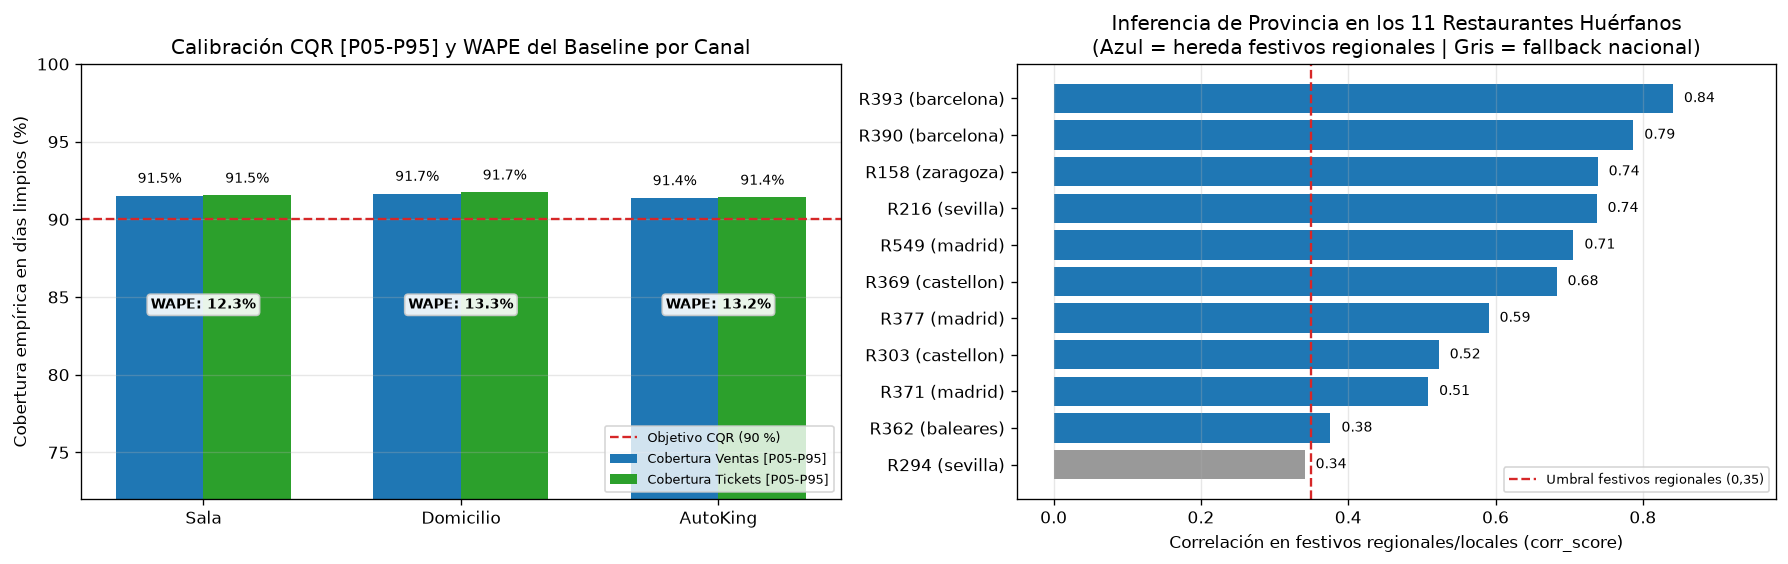

In [9]:
# Calibración CQR por canal (cobertura [P05, P95] + WAPE) e inferencia de los 11 restaurantes huérfanos
fig_dir = REPO_ROOT / "docs" / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

# Panel A: Cobertura CQR y WAPE por canal
canales = ["sala", "domicilio", "autoking"]
cov_v_ch, cov_t_ch, wape_ch = [], [], []
for ch in canales:
    m = clean_eval & (df_feat["canal"] == ch)
    sub = df_feat.loc[m]
    cov_v_ch.append(100.0 * float(((sub["ventas"] >= sub["ventas_p05"]) & (sub["ventas"] <= sub["ventas_p95"])).mean()))
    cov_t_ch.append(100.0 * float(((sub["tickets"] >= sub["tickets_p05"]) & (sub["tickets"] <= sub["tickets_p95"])).mean()))
    wape_ch.append(100.0 * float((sub["ventas"] - sub["ventas_esperadas"]).abs().sum() / sub["ventas"].sum()))

x = np.arange(len(canales))
w = 0.34
b1 = axes[0].bar(x - w / 2, cov_v_ch, w, label="Cobertura Ventas [P05-P95]", color="#1f77b4")
b2 = axes[0].bar(x + w / 2, cov_t_ch, w, label="Cobertura Tickets [P05-P95]", color="#2ca02c")
axes[0].axhline(90.0, color="#d62728", ls="--", lw=1.4, label="Objetivo CQR (90 %)")
for i, (r1, r2, wp) in enumerate(zip(b1, b2, wape_ch)):
    axes[0].text(r1.get_x() + r1.get_width() / 2, r1.get_height() + 0.6, f"{r1.get_height():.1f}%", ha="center", va="bottom", fontsize=8.5)
    axes[0].text(r2.get_x() + r2.get_width() / 2, r2.get_height() + 0.6, f"{r2.get_height():.1f}%", ha="center", va="bottom", fontsize=8.5)
    axes[0].text(x[i], 84.5, f"WAPE: {wp:.1f}%", ha="center", va="center", fontsize=8.5, fontweight="bold",
                 bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="#cccccc", alpha=0.9))
axes[0].set_xticks(x)
axes[0].set_xticklabels(["Sala", "Domicilio", "AutoKing"])
axes[0].set_ylim(72, 100)
axes[0].set_ylabel("Cobertura empírica en días limpios (%)")
axes[0].set_title("Calibración CQR [P05-P95] y WAPE del Baseline por Canal")
axes[0].legend(loc="lower right", fontsize=8)
axes[0].grid(axis="y", alpha=0.3)

# Panel B: 11 restaurantes huérfanos (corr_score vs umbral 0.35)
orph_plot = orphan_df.sort_values("corr_score", ascending=True)
labels_o = [f"{r.restaurante_id} ({r.provincia_inferida})" for r in orph_plot.itertuples()]
cols_o = ["#1f77b4" if v >= 0.35 else "#999999" for v in orph_plot["corr_score"]]
bars_o = axes[1].barh(labels_o, orph_plot["corr_score"], color=cols_o)
axes[1].axvline(0.35, color="#d62728", ls="--", lw=1.4, label="Umbral festivos regionales (0,35)")
for bar, val in zip(bars_o, orph_plot["corr_score"]):
    axes[1].text(max(val, 0.0) + 0.015, bar.get_y() + bar.get_height() / 2, f"{val:.2f}", va="center", fontsize=8.5)
axes[1].set_xlim(min(-0.05, float(orph_plot["corr_score"].min()) - 0.05), min(1.05, float(orph_plot["corr_score"].max()) + 0.14))
axes[1].set_xlabel("Correlación en festivos regionales/locales (corr_score)")
axes[1].set_title("Inferencia de Provincia en los 11 Restaurantes Huérfanos\n(Azul = hereda festivos regionales | Gris = fallback nacional)")
axes[1].legend(loc="lower right", fontsize=8)
axes[1].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(fig_dir / "01_cqr_calibracion_y_huerfanos.png", dpi=180, bbox_inches="tight")
plt.show()
